# My Notebook: GDP vs Development
**Question:** Do richer countries have higher literacy, more people living in cities, and more internet access? And which countries do better or worse than their GDP would predict?

I follow the same flow as the original (load → summary → skew → relationships → correlation → scatter), with my own code and explanations.

**My improvements:**
1. **Data check:** look for missing or impossible values before analyzing.
2. **Log-transform GDP:** fixes the skew and makes the relationships much clearer.
3. **A reusable function** that plots GDP vs any indicator, with country labels and a trend line.
4. **Pearson vs. Spearman correlation**, to show the relationships are curved.
5. **Income groups** (low / middle / high) compared with a grouped bar chart.
6. **Over- and under-performers:** which countries do better or worse than their GDP predicts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
url = "https://raw.githubusercontent.com/duochen/data-science-bootcamp/refs/heads/main/Data/gdp_development.csv"
data = pd.read_csv(url)

# shorter column names are easier to type
data = data.rename(columns={
    "GDP per Capita": "gdp",
    "Literacy Rate": "literacy",
    "Urban Population (%)": "urban",
    "Internet Access (%)": "internet",
})
indicators = ["literacy", "urban", "internet"]
labels = {"literacy": "Literacy rate (%)", "urban": "Urban population (%)", "internet": "Internet access (%)"}
data

,Country,gdp,literacy,urban,internet
0,Germany,50000,99,77,92
1,United States,65000,99,83,89
2,India,2200,74,35,41
3,Nigeria,2000,62,50,42
4,Brazil,8700,93,87,75
5,China,10500,97,61,65
6,Norway,82000,100,83,98
7,Bangladesh,1900,73,39,39
8,South Africa,6000,87,67,68
9,Canada,48000,99,82,91


## 2. Improvement #1: check the data first

In [3]:
print("Missing values:\n", data.isna().sum(), sep="")

# percentages must be between 0 and 100, GDP must be positive
bad = data[(data[indicators].lt(0) | data[indicators].gt(100)).any(axis=1) | (data["gdp"] <= 0)]
print("\nRows with impossible values:", len(bad))

clean = data.dropna().copy()   # would drop incomplete rows if there were any
print("Rows kept:", len(clean), "of", len(data))

Missing values:
Country     0
gdp         0
literacy    0
urban       0
internet    0
dtype: int64

Rows with impossible values: 0
Rows kept: 10 of 10


All 10 countries are complete and valid. Only 10 countries is a small sample, so the results are patterns, not proof.

## 3. Summary statistics and skew

In [4]:
clean[["gdp"] + indicators].describe().round(1)

,gdp,literacy,urban,internet
count,10.0,10.0,10.0,10.0
mean,27630.0,88.3,66.4,70.0
std,30465.3,13.8,19.3,22.9
min,1900.0,62.0,35.0,39.0
25%,3150.0,77.2,52.8,47.8
50%,9600.0,95.0,72.0,71.5
75%,49500.0,99.0,82.8,90.5
max,82000.0,100.0,87.0,98.0


In [5]:
print("Skewness:")
print(clean[["gdp"] + indicators].skew().round(2))

Skewness:
gdp         0.79
literacy   -0.99
urban      -0.64
internet   -0.32
dtype: float64


GDP is **right-skewed** (+0.79): the mean ($27,630) is almost 3× the median ($9,600) because a few very rich countries pull it up. Literacy is **left-skewed** (−0.99) because most countries are close to the 100% ceiling.

## 4. Improvement #2: log-transform GDP
Money grows by multiplying (a country going from \$2k to \$20k is like going from \$20k to \$200k), so a **log scale** fits GDP better. `log10(gdp)` = 3 means \$1,000, 4 means \$10,000, and so on.

Skew of GDP:       0.79
Skew of log10 GDP: 0.02


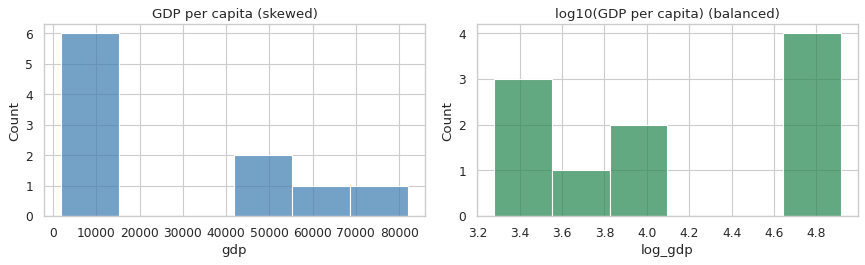

In [6]:
clean["log_gdp"] = np.log10(clean["gdp"])

print("Skew of GDP:      ", round(clean["gdp"].skew(), 2))
print("Skew of log10 GDP:", round(clean["log_gdp"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(clean["gdp"], bins=6, ax=axes[0], color="steelblue")
axes[0].set_title("GDP per capita (skewed)")
sns.histplot(clean["log_gdp"], bins=6, ax=axes[1], color="seagreen")
axes[1].set_title("log10(GDP per capita) (balanced)")
plt.tight_layout()
plt.show()

After the log, the skew drops from 0.79 to about 0.02, so the countries are spread out evenly instead of bunched at the low end.

## 5. Overview: pairplot

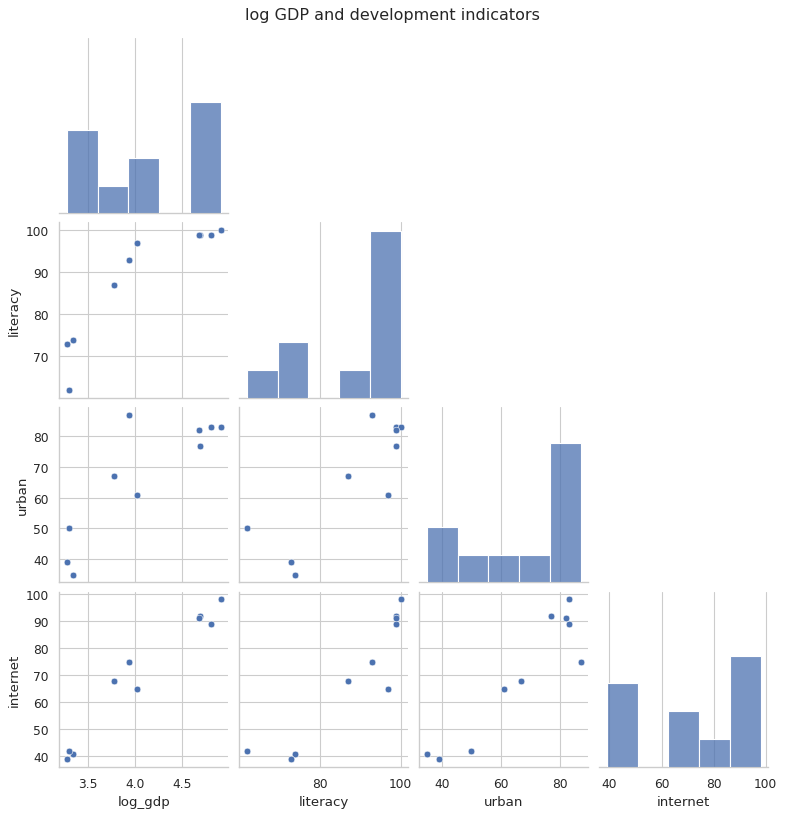

In [7]:
g = sns.pairplot(clean[["log_gdp"] + indicators], corner=True, diag_kind="hist")
g.figure.suptitle("log GDP and development indicators", y=1.02)
plt.show()

## 6. Improvement #4: Pearson vs. Spearman correlation
**Pearson** measures straight-line relationships. **Spearman** only compares the *ranking* of countries, so it also catches curved relationships.

,Pearson (GDP),Pearson (log GDP),Spearman (GDP)
literacy,0.72,0.90,0.98
urban,0.70,0.85,0.74
internet,0.87,0.97,0.92


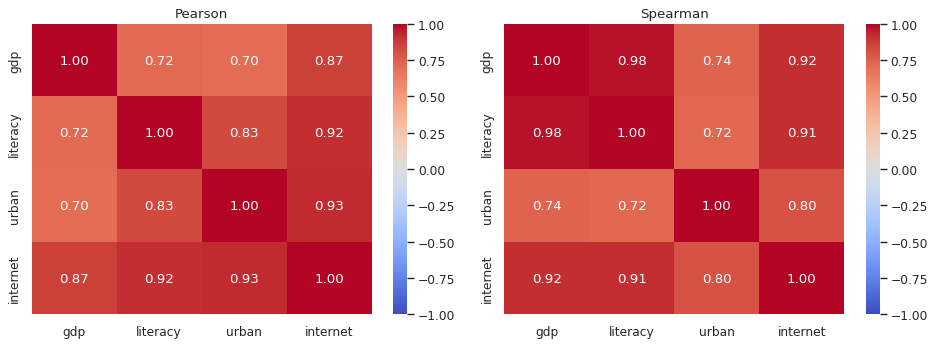

In [8]:
cols = ["gdp"] + indicators
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(clean[cols].corr(method=method), annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(method.capitalize())
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Pearson (GDP)":     clean[indicators].corrwith(clean["gdp"]),
    "Pearson (log GDP)": clean[indicators].corrwith(clean["log_gdp"]),
    "Spearman (GDP)":    clean[indicators].corrwith(clean["gdp"], method="spearman"),
}).round(2)
comparison

The biggest change is **literacy**: Pearson with raw GDP is only 0.72, but Spearman is **0.98**: richer countries almost always rank higher in literacy. Using log GDP also raises every Pearson value (literacy 0.90, urban 0.85, internet 0.97). So the relationships are strong; they just aren't straight lines on a regular scale.

## 7. Improvement #3: one function for every scatter plot

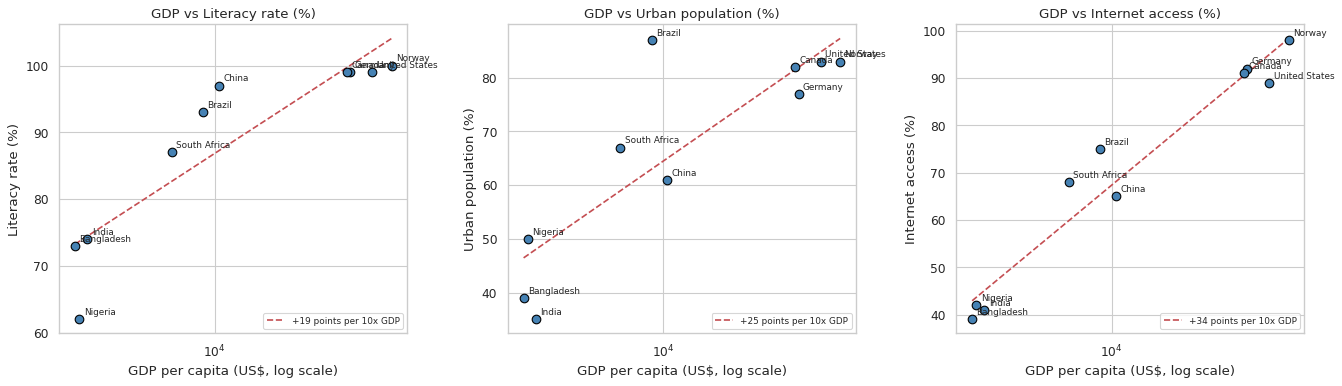

In [9]:
def plot_vs_gdp(df, col, ax):
    """Scatter of log-scale GDP vs `col`, with country labels and a trend line."""
    ax.scatter(df["gdp"], df[col], s=60, color="steelblue", edgecolor="black", zorder=3)
    for _, r in df.iterrows():
        ax.annotate(r["Country"], (r["gdp"], r[col]), xytext=(4, 4),
                    textcoords="offset points", fontsize=8)
    slope, intercept = np.polyfit(df["log_gdp"], df[col], 1)   # straight line on log(GDP)
    xs = np.logspace(df["log_gdp"].min(), df["log_gdp"].max(), 50)
    ax.plot(xs, intercept + slope * np.log10(xs), "r--",
            label=f"+{slope:.0f} points per 10x GDP")
    ax.set_xscale("log")
    ax.set_xlabel("GDP per capita (US$, log scale)")
    ax.set_ylabel(labels[col])
    ax.set_title(f"GDP vs {labels[col]}")
    ax.legend(fontsize=8, loc="lower right")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, indicators):
    plot_vs_gdp(clean, col, ax)
plt.tight_layout()
plt.show()

With labels and a log scale, every country is readable. For each **10× increase in GDP**, literacy goes up about 19 points, urban population about 25 points, and internet access about 34 points. Internet access is the indicator most tied to wealth. (The literacy trend line goes above 100% for the richest countries, which is impossible — another sign the real pattern is curved and levels off.)

## 8. Improvement #5: income groups

income_group
Low (<$5k)                      [India, Nigeria, Bangladesh]
Middle ($5k–20k)               [Brazil, China, South Africa]
High (>$20k)        [Germany, United States, Norway, Canada]
Name: Country, dtype: object


,Literacy rate (%),Urban population (%),Internet access (%)
income_group,,,
Low (<$5k),69.7,41.3,40.7
Middle ($5k–20k),92.3,71.7,69.3
High (>$20k),99.2,81.2,92.5


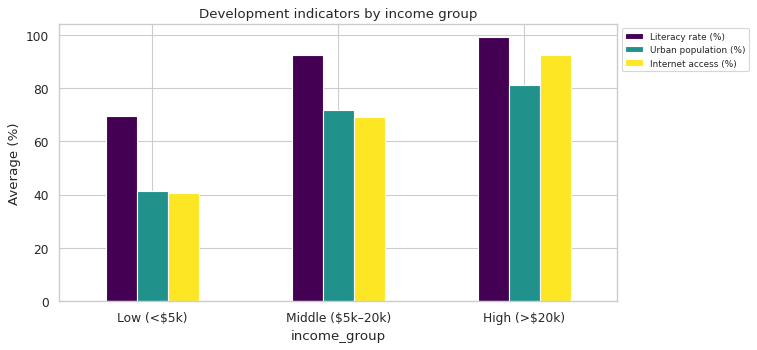

In [10]:
clean["income_group"] = pd.cut(clean["gdp"], bins=[0, 5000, 20000, np.inf],
                               labels=["Low (<$5k)", "Middle ($5k–20k)", "High (>$20k)"])
print(clean.groupby("income_group", observed=True)["Country"].apply(list))

group_means = clean.groupby("income_group", observed=True)[indicators].mean().round(1)
group_means.columns = [labels[c] for c in indicators]
group_means.plot(kind="bar", figsize=(9, 4.5), rot=0, colormap="viridis")
plt.ylabel("Average (%)")
plt.title("Development indicators by income group")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.show()
group_means

Every indicator rises from low → middle → high income. The biggest jump is from low to middle income (for example, internet access goes from about 41% to 69%). After that, the gains get smaller, especially for literacy, which is already near 100%.

## 9. Improvement #6: who beats (or misses) their GDP?
The **residual** = actual value − value predicted by the trend line. Positive means the country does *better* than its GDP predicts.

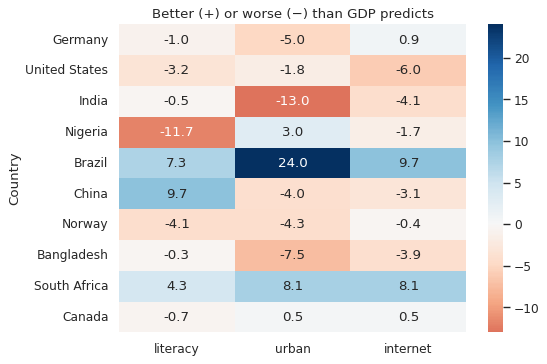

In [11]:
residuals = pd.DataFrame({"Country": clean["Country"]})
for col in indicators:
    slope, intercept = np.polyfit(clean["log_gdp"], clean[col], 1)
    residuals[col] = (clean[col] - (intercept + slope * clean["log_gdp"])).round(1)
residuals = residuals.set_index("Country")

plt.figure(figsize=(7, 5))
sns.heatmap(residuals, annot=True, fmt=".1f", cmap="RdBu", center=0)
plt.title("Better (+) or worse (−) than GDP predicts")
plt.show()

- **Brazil** is far more urban than its GDP predicts (+24 points).
- **China** has higher literacy than predicted (+10), an "education success story" like the original notebook mentioned.
- **Nigeria** has much lower literacy than predicted (−12).
- **India** is less urban than predicted (−13).

This shows GDP explains a lot, but history, geography and government policy matter too.

## 10. Summary
| Analysis | What I found |
|---|---|
| Data check | No missing or impossible values; only 10 countries |
| Skew | GDP right-skewed (0.79); after log ≈ 0 |
| Correlation | All strong and positive; literacy Pearson 0.72 vs Spearman 0.98 → curved |
| Trend per 10× GDP | Literacy +19, Urban +25, Internet +34 points |
| Income groups | Biggest jump from low → middle income |
| Residuals | Brazil (urban) and China (literacy) beat their GDP; Nigeria (literacy) and India (urban) fall short |

## 11. Reflection
*(Draft — rewrite this in your own words before submitting.)*

This notebook was about how a country's wealth (GDP per capita) relates to its development: literacy, urban population and internet access. The original used summary statistics, skewness, a pairplot, a correlation heatmap and one scatter plot. In my version I checked the data first, and then log-transformed GDP because it was very skewed. I also wrote a function that draws a labeled scatter plot with a trend line for every indicator, compared Pearson and Spearman correlation, grouped countries by income, and calculated which countries do better or worse than their GDP predicts. I learned that a correlation number can hide a strong relationship if the pattern is curved: literacy looked only moderately linked to GDP (0.72), but by rank it was almost perfect (0.98). I also learned that log scales are useful for money, and that looking at the exceptions, like Brazil and China, is as interesting as the overall trend. Finally, with only 10 countries, these results are a starting point, not a final conclusion.